In [47]:
import pandas as pd
import seaborn as sb
import statistics as st

# Importando Dados

In [48]:
ds = pd.read_csv(r'C:\Users\felip\Formação Cientista de Dados\10.Prática em Python\dados\tempo.csv', sep=';')

In [49]:
ds

,X1,X2,X3,X4,X5
0,sol,85,85.0,FALSO,nao
1,sol,80,90.0,VERDADEIRO,nao
2,nublado,83,86.0,FALSO,sim
3,chuva,70,NaN,FALSO,sim
4,chuva,68,80.0,FALSO,sim
5,chuva,65,70.0,VERDADEIRO,nao
6,menos,64,65.0,VERDADEIRO,sim
7,sol,1220,95.0,FALSO,nao
8,sol,69,70.0,FALSO,sim
9,chuva,75,200.0,NaN,sim


In [50]:
ds.columns = ['Aparencia', 'Temperatura', 'Umidade', 'Vento', 'Jogar']

In [51]:
ds

,Aparencia,Temperatura,Umidade,Vento,Jogar
0,sol,85,85.0,FALSO,nao
1,sol,80,90.0,VERDADEIRO,nao
2,nublado,83,86.0,FALSO,sim
3,chuva,70,NaN,FALSO,sim
4,chuva,68,80.0,FALSO,sim
5,chuva,65,70.0,VERDADEIRO,nao
6,menos,64,65.0,VERDADEIRO,sim
7,sol,1220,95.0,FALSO,nao
8,sol,69,70.0,FALSO,sim
9,chuva,75,200.0,NaN,sim


# Tratando ['Aparencia']

In [52]:
agrupado = ds.groupby(['Aparencia']).size()
agrupado

Aparencia
chuva      5
menos      1
nublado    3
sol        5
dtype: int64

In [53]:
moda = st.mode(ds['Aparencia'])
moda

'sol'

In [54]:
ds.loc[(ds['Aparencia'] != 'chuva') &
       (ds['Aparencia'] != 'sol') &
       (ds['Aparencia'] != 'nublado'), 'Aparencia'] = moda
agrupado = ds.groupby(['Aparencia']).size()

In [55]:
agrupado

Aparencia
chuva      5
nublado    3
sol        6
dtype: int64

# Tratando ['Temperatura']

In [56]:
agrupado = ds.groupby('Temperatura').size()
agrupado

Temperatura
64      1
65      1
68      1
69      1
70      1
71      1
72      1
75      2
80      1
81      1
83      1
85      1
1220    1
dtype: int64

In [91]:
ds.loc[(ds['Temperatura'] < -130) | (ds['Temperatura'] > 130)]

,Aparencia,Temperatura,Umidade,Vento,Jogar


In [58]:
mediana = int(st.median(ds['Temperatura']))
mediana

73

In [59]:
ds.loc[(ds['Temperatura'] < -130) | (ds['Temperatura'] > 130), 'Temperatura'] = mediana

In [60]:
agrupado = ds.groupby('Temperatura').size()
agrupado

Temperatura
64    1
65    1
68    1
69    1
70    1
71    1
72    1
73    1
75    2
80    1
81    1
83    1
85    1
dtype: int64

# Tratando ['Umidade']

In [61]:
agrupado = ds.groupby('Umidade').size()
agrupado

Umidade
65.0     1
70.0     3
75.0     1
80.0     1
85.0     1
86.0     1
90.0     2
91.0     1
95.0     1
200.0    1
dtype: int64

In [62]:
ds.loc[(ds['Umidade'] < 0) | (ds['Umidade'] > 100)]

,Aparencia,Temperatura,Umidade,Vento,Jogar
9,chuva,75,200.0,NaN,sim


In [63]:
mediana = int(st.median(ds['Umidade']))
mediana

85

In [64]:
ds.loc[(ds['Umidade'] < 0) | (ds['Umidade'] > 100), 'Umidade'] = mediana

In [65]:
agrupado = ds.groupby('Umidade').size()
agrupado

Umidade
65.0    1
70.0    3
75.0    1
80.0    1
85.0    2
86.0    1
90.0    2
91.0    1
95.0    1
dtype: int64

# Tratar ['Jogar']

In [66]:
agrupado = ds.groupby('Jogar').size()
agrupado

Jogar
nao    5
sim    9
dtype: int64

In [67]:
moda = st.mode(ds['Jogar'])
moda

'sim'

In [68]:
ds.loc[(ds['Jogar'] != 'sim') & (ds['Jogar'] != 'nao')]

,Aparencia,Temperatura,Umidade,Vento,Jogar


In [69]:
ds.loc[(ds['Jogar'] != 'sim') & (ds['Jogar'] != 'nao'), 'Jogar'] = moda

In [70]:
agrupado = ds.groupby('Jogar').size()
agrupado

Jogar
nao    5
sim    9
dtype: int64

# Tratar valores NAs

In [71]:
ds.isna().sum()

Aparencia      0
Temperatura    0
Umidade        1
Vento          1
Jogar          0
dtype: int64

['Umidade']

In [72]:
agrupado = ds.groupby('Umidade').size()
agrupado

Umidade
65.0    1
70.0    3
75.0    1
80.0    1
85.0    2
86.0    1
90.0    2
91.0    1
95.0    1
dtype: int64

In [73]:
mediana = int(st.median(ds['Umidade']))
mediana

85

In [74]:
ds['Umidade'].fillna(mediana, inplace=True)
ds.loc[(ds['Umidade'] < 0) | (ds['Umidade'] > 100), 'Umidade'] = mediana

In [75]:
agrupado = ds.groupby('Umidade').size()
agrupado

Umidade
65.0    1
70.0    3
75.0    1
80.0    1
85.0    3
86.0    1
90.0    2
91.0    1
95.0    1
dtype: int64

['Vento']

In [76]:
agrupado = ds.groupby('Vento').size()
agrupado

Vento
FALSO         7
VERDADEIRO    6
dtype: int64

In [77]:
moda = st.mode(ds['Vento'])
moda

'FALSO'

In [78]:
ds.loc[(ds['Vento'] != 'VERDADEIRO') & (ds['Vento'] != 'FALSO'), 'Vento'] = moda

In [79]:
ds['Vento'].fillna(moda, inplace=True)

In [80]:
agrupado = ds.groupby('Vento').size()
agrupado

Vento
FALSO         8
VERDADEIRO    6
dtype: int64

<AxesSubplot:xlabel='Aparencia', ylabel='Count'>

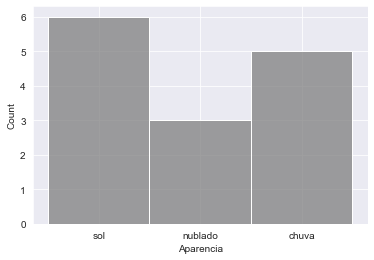

In [81]:
sb.histplot(ds['Aparencia'], color='grey')

<AxesSubplot:xlabel='Temperatura', ylabel='Count'>

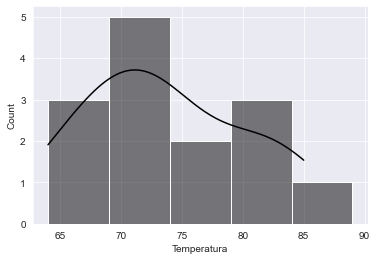

In [82]:
sb.histplot(ds['Temperatura'], color='black', binwidth=5, kde=True)

<AxesSubplot:xlabel='Umidade', ylabel='Count'>

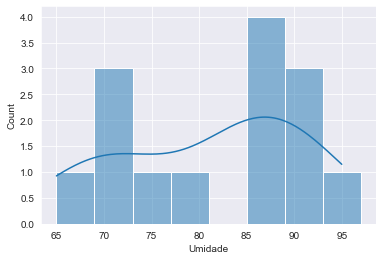

In [83]:
sb.histplot(data=ds['Umidade'], binwidth=4, kde=True)

<AxesSubplot:xlabel='Vento', ylabel='Count'>

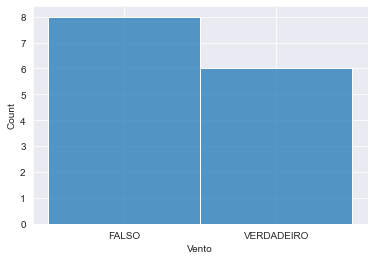

In [84]:
sb.histplot(ds['Vento'])

<AxesSubplot:xlabel='Jogar', ylabel='Count'>

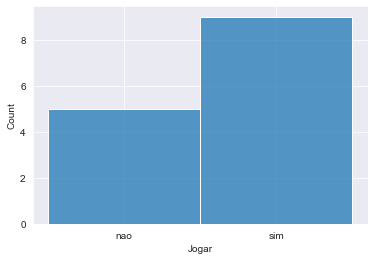

In [85]:
sb.histplot(data=ds['Jogar'])